# Customer Churn Prediction

## Phase 4: Model Training

### Objectives
- Load preprocessed data
- Train Logistic Regression
- Make predictions
- Evaluate classification performance
- Understand classification metrics

# Import Libraries 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Load Preprocessed Data

In [2]:
data = joblib.load("../data/processed/processed_data.pkl")

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (4929, 50)
Validation: (1057, 50)
Test: (1057, 50)


### Convert target into numeric

In [3]:
y_train = y_train.map({"No": 0, "Yes": 1})
y_val = y_val.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})

print(y_train.value_counts())

Churn
0    3621
1    1308
Name: count, dtype: int64


### Create a Baseline Model

In [4]:
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_val)

In [5]:
print("Baseline Accuracy:",
      accuracy_score(y_val, dummy_predictions))

print("Baseline Precision:",
      precision_score(y_val, dummy_predictions, zero_division=0))

print("Baseline Recall:",
      recall_score(y_val, dummy_predictions, zero_division=0))

print("Baseline F1:",
      f1_score(y_val, dummy_predictions, zero_division=0))

Baseline Accuracy: 0.7341532639545885
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1: 0.0


# Train Logistic Regression

In [6]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


# Make Predictions

In [7]:
# Predict class labels
y_val_pred = logistic_model.predict(X_val)

# Predict churn probabilities
y_val_proba = logistic_model.predict_proba(X_val)[:, 1]

In [8]:
print("Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("Precision:",
      precision_score(y_val, y_val_pred))

print("Recall:",
      recall_score(y_val, y_val_pred))

print("F1 Score:",
      f1_score(y_val, y_val_pred))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_proba))

print("PR-AUC (Average Precision):",
      average_precision_score(y_val, y_val_proba))

Accuracy: 0.7483443708609272
Precision: 0.5177304964539007
Recall: 0.7793594306049823
F1 Score: 0.6221590909090909
ROC-AUC: 0.8328411050372382
PR-AUC (Average Precision): 0.6392715936551433


# Confusion Matrix

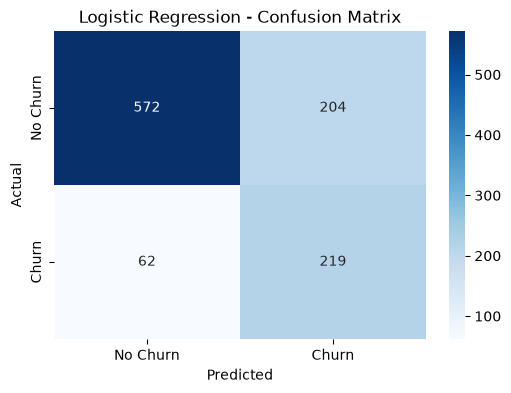

In [9]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

# Classification Report

In [10]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81       776
       Churn       0.52      0.78      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057



# Train Decision Tree

In [11]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [12]:
dt_pred = decision_tree.predict(X_val)
dt_proba = decision_tree.predict_proba(X_val)[:, 1]

# Train Random Forest

In [13]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [14]:
rf_pred = random_forest.predict(X_val)
rf_proba = random_forest.predict_proba(X_val)[:, 1]

# Train XGBoost

In [15]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [16]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [17]:
xgb_pred = xgb_model.predict(X_val)
xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

# Train K-Nearest Neighbors (KNN)

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski"
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_val)
knn_proba = knn_model.predict_proba(X_val)[:, 1]

print("KNN training completed!")

KNN training completed!


# Train Support Vector Machine (SVM)

In [19]:
from sklearn.svm import SVC

svm_model = SVC(
    C=1.0,
    kernel="rbf",
    probability=True,
    class_weight="balanced",
    random_state=42
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_val)
svm_proba = svm_model.predict_proba(X_val)[:, 1]

print("SVM training completed!")

/opt/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!


# Train Naive Bayes

In [20]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_val)
nb_proba = nb_model.predict_proba(X_val)[:, 1]

print("Naive Bayes training completed!")

Naive Bayes training completed!


# Train Gradient Boosting

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_val)
gb_proba = gb_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


# Model Evaluation Function

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

def evaluate_model(name, y_true, y_pred, y_proba):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC (AP)": average_precision_score(y_true, y_proba)
    }

# Compare All Models

In [24]:
results = []

# Logistic Regression
results.append(
    evaluate_model(
        "Logistic Regression",
        y_val,
        y_val_pred,
        y_val_proba
    )
)

# Decision Tree
results.append(
    evaluate_model(
        "Decision Tree",
        y_val,
        dt_pred,
        dt_proba
    )
)

# Random Forest
results.append(
    evaluate_model(
        "Random Forest",
        y_val,
        rf_pred,
        rf_proba
    )
)

# XGBoost
results.append(
    evaluate_model(
        "XGBoost",
        y_val,
        xgb_pred,
        xgb_proba
    )
)

# K-Nearest Neighbors (KNN)
results.append(
    evaluate_model(
        "KNN",
        y_val,
        knn_pred,
        knn_proba
    )
)
# Support Vector Machine (SVM)
results.append(
    evaluate_model(
        "SVM",
        y_val,
        svm_pred,
        svm_proba
    )
)

# Naive Bayes
results.append(
    evaluate_model(
        "Naive Bayes",
        y_val,
        nb_pred,
        nb_proba
    )
)

# Gradient Boosting
results.append(
    evaluate_model(
        "Gradient Boosting",
        y_val,
        gb_pred,
        gb_proba
    )
)


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC (AP)",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
3,XGBoost,0.751183,0.521429,0.779359,0.624822,0.837606,0.642633
7,Gradient Boosting,0.798486,0.666667,0.483986,0.560825,0.837943,0.640355
2,Random Forest,0.761589,0.536341,0.761566,0.629412,0.834740,0.639461
0,Logistic Regression,0.748344,0.517730,0.779359,0.622159,0.832841,0.639272
5,SVM,0.742668,0.510791,0.758007,0.610315,0.812566,0.606227
6,Naive Bayes,0.688742,0.452000,0.804270,0.578745,0.801730,0.580397
1,Decision Tree,0.740776,0.508557,0.740214,0.602899,0.814201,0.577907
4,KNN,0.759697,0.555102,0.483986,0.517110,0.757620,0.519537


# Visualize Model Comparison

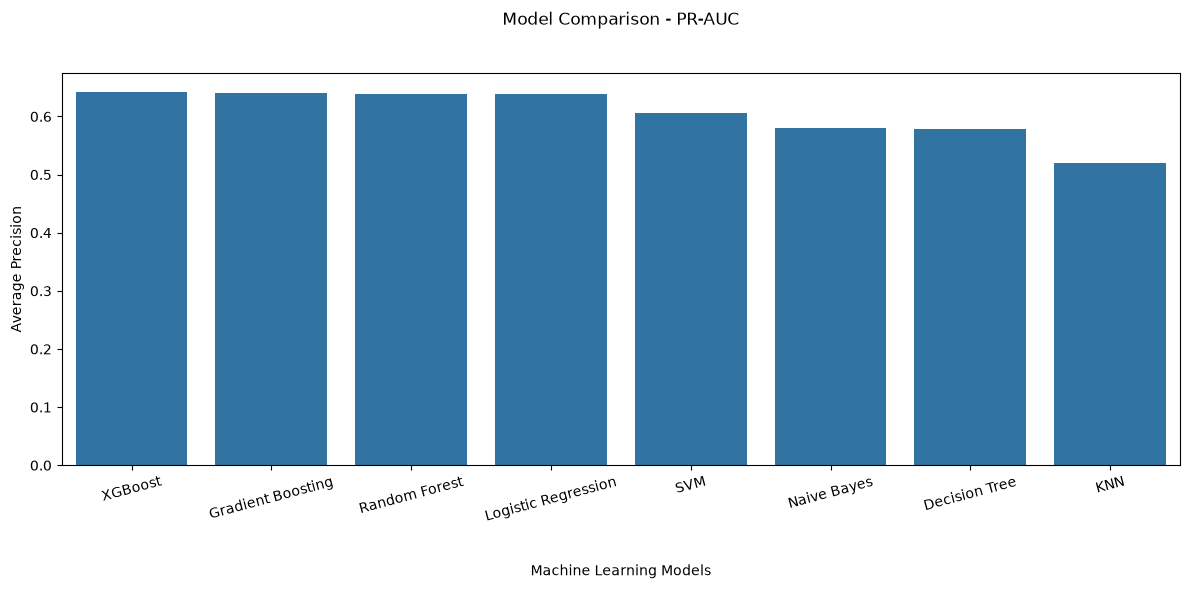

In [30]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC (AP)"
)

plt.title("Model Comparison - PR-AUC\n\n")
plt.xlabel("\n\nMachine Learning Models")
plt.ylabel("Average Precision")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()